In [ ]:
import pandas as pd

df= pd.read_excel("/home/s0shar47/scratch/salil/GAGES-2/gagesII_mar1_2013_conterm.xlsx",sheet_name='Hydro')
df= pd.DataFrame(df.set_index('STAID')['BFI_AVE'])
df.reset_index(inplace=True)

In [3]:
import numpy as np
import pandas as pd

bfi_sim = []
gauges = []

bfi_sim_old= [] 

for i in range(1, 11):
    # Load gage ids
    gage_id = np.load(
        f"/home/s0shar47/scratch/BASEFLOW_FOLDS/{i}/test/DAYMET_19800101_20141231_forcing_baseflow_mmday.npy"
    )
    gage_id = gage_id[:, 0, -2].astype(int)  # Convert to integer right away

    # Load simulated BFI
    bfim = np.load(
        # f"/home/s0shar47/scratch/DAYMET_BASEFLOW_OUTPUTS/{i}/LSTM_HBV_E50_R365_B100_H256_tr1989_1999_n16_111111/parBETA_parBETAET_/ts1989_1999/BFI_sim.npy"
        f"/home/s0shar47/scratch/Outputs Multi Objective/HBV_capillary/{i}/LSTM_HBV_capillary_E50_R365_B100_H256_tr1989_1999_n16_111111/parBETA_parBETAET_parK0_parUZL_/ts1989_1999/BFI_sim.npy"
    )

    bfio= np.load(
    # f"/home/s0shar47/scratch/DAYMET_BASEFLOW_OUTPUTS_test2/{i}/LSTM_HBV_E50_R365_B100_H256_tr1989_1999_n16_111111/parBETA_parBETAET_/ts1980_2014/BFI_sim.npy"
                  f"/home/s0shar47/scratch/Outputs Single Objective/HBV_capillary/{i}/LSTM_HBV_capillary_E50_R365_B100_H256_tr1989_1999_n16_111111/parBETA_parBETAET_parK0_parUZL_/ts1989_1999/BFI_sim.npy"
                  )

    # Append the raw numpy arrays
    gauges.append(gage_id)
    bfi_sim.append(bfim)
    bfi_sim_old.append(bfio)

# Concatenate all 10 folds into flat 1D numpy arrays
flat_gauges = np.concatenate(gauges)
flat_bfi = np.concatenate(bfi_sim)
flat_bfio = np.concatenate(bfi_sim_old)

# Create a clean, flat DataFrame
dfd = pd.DataFrame({"STAID": flat_gauges, "Simulated BFI (Multi)": flat_bfi, "Simulated BFI (Single)": flat_bfio})

dff=dfd.merge(df, on='STAID', how='inner')

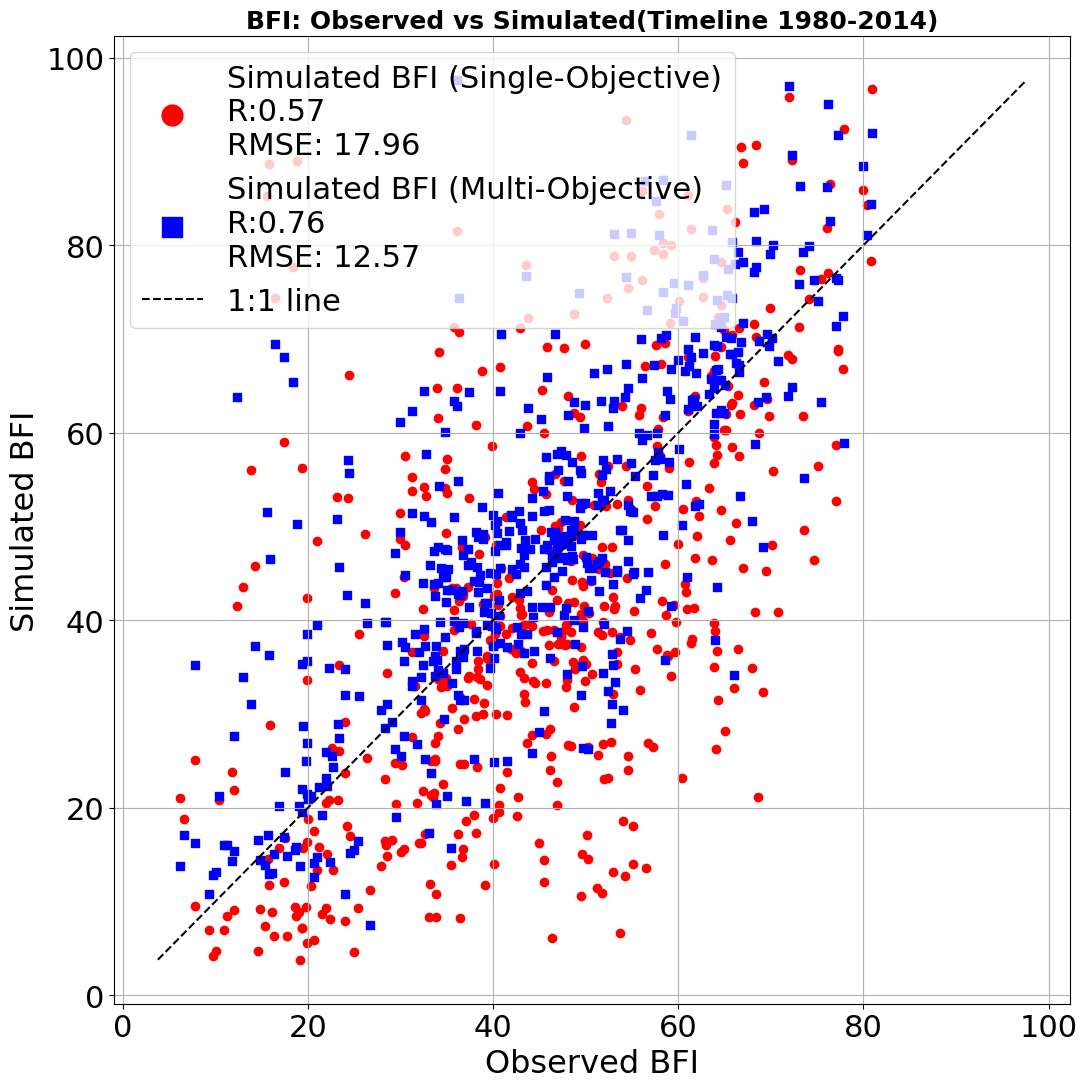

In [4]:
import matplotlib.pyplot as plt
import numpy as np

# Extract arrays
x = dff['BFI_AVE'].values
y1 = dff['Simulated BFI (Single)'].values
y2 = dff['Simulated BFI (Multi)'].values

corr1= dff['BFI_AVE'].corr(dff['Simulated BFI (Single)'])
rmse1= np.sqrt(((dff['BFI_AVE']-dff['Simulated BFI (Single)'])**2).mean())
corr2= dff['BFI_AVE'].corr(dff['Simulated BFI (Multi)'])
rmse2= np.sqrt(((dff['BFI_AVE']-dff['Simulated BFI (Multi)'])**2).mean())

plt.figure(figsize=(11,11))

# Scatter plots
plt.scatter(x, y1, marker='o', label= f'Simulated BFI (Single-Objective)\nR:{corr1:.2f}\nRMSE: {rmse1:.2f}', color='red')
plt.scatter(x, y2, marker='s', label= f'Simulated BFI (Multi-Objective)\nR:{corr2:.2f}\nRMSE: {rmse2:.2f}', color='blue')

# 1:1 line
min_val = min(np.min(x), np.min(y1), np.min(y2))
max_val = max(np.max(x), np.max(y1), np.max(y2))
plt.plot([min_val, max_val], [min_val, max_val], 'k--', label='1:1 line')

# Labels and styling
plt.xlabel('Observed BFI', fontsize=23)
plt.xticks(fontsize=22)
plt.ylabel('Simulated BFI', fontsize=23)
plt.yticks(fontsize=22)
plt.title('BFI: Observed vs Simulated(Timeline 1980-2014)', fontsize=18, fontweight='bold')
plt.legend(
    fontsize=22,
    markerscale=2.5,   # Increase marker size in legend
    scatterpoints=1
)
plt.grid(True)

plt.tight_layout()
plt.show()

In [ ]:
# 1. Clean the gage_ids into a clean integer list
gage_ids_int = gage_id.astype(int)

# 2. Re-index the dataframe to match the exact order of your array
# (This automatically pulls only the gauges you need, in the right order)
df_ordered = df.set_index("STAID").reindex(gage_ids_int)

# 3. Pull the observed column (e.g., 'BFI_AVE') as a numpy array
# (Missing gauges will automatically result in NaN)
bfi_obs_array = df_ordered["BFI_AVE"].values

# 4. Do the math across the whole array instantly
differences = bfi - bfi_obs_array

# Print the first 10 differences to verify
print(differences[:53])

[ -2.65377957   2.81529076  11.55659179   7.29660886   6.96778587
 -11.80909116   6.82482369   8.98374999   1.33052483   8.13546091
 -17.0237833   -4.01484915 -18.31568225   1.42499356   3.42625944
  11.05612423   9.23742195  11.99968891  -6.97372054   3.19458818
  -4.28785943   9.95290486  17.47164933   1.55060858   8.79726147
   0.10413819   0.56444653  41.8368908   10.3887067   -1.83017577
   4.43931581  -5.70783512  16.75793172   6.83162224   6.24517391
  -0.18105524   7.71743489  12.23017123   1.368703     0.4597896
   7.28906352   4.68609096   7.78585328   0.87981019  -6.41705822
   6.40751291   3.6055871   -6.70583087  -1.43431743  -3.81256269
   2.64211939 -11.46403138]


In [ ]:
####USGS SEPARATION on 2003 conversion to mm/day
import numpy as np

# --------------------------------------------------
# Load data
# --------------------------------------------------

forc = np.load(
    "/home/s0shar47/scratch/f2003_daymet_20240826_baseflow.npy",
    allow_pickle=True,
)

attr = np.load(
    "/home/s0shar47/scratch/salil/dPL_Hydro_SNTEMP/Rahmani, Farshid's files - dPL_Hydro_SNTEMP/attr_2003_daymet_20241107.npy",
    allow_pickle=True,
)

print(forc.shape)
print(attr.shape)

# --------------------------------------------------
# Convert baseflow from m3/day to mm/day
# --------------------------------------------------

AREA_IDX = 27          # DRAIN_SQKM
BASEFLOW_IDX = 16      # last variable

area_km2 = attr[:, AREA_IDX].astype(float)

# m3/day -> mm/day
forc[:, :, BASEFLOW_IDX] = (
    forc[:, :, BASEFLOW_IDX].astype(float)
    / (area_km2[:, None] * 1000.0)
)

# --------------------------------------------------
# Save
# --------------------------------------------------

out_file = "/home/s0shar47/scratch/f2003_daymet_20240826_baseflow_mmday.npy"

np.save(out_file, forc)

print("Saved to:", out_file)

(2003, 15706, 17)
(2003, 64)
Saved to: /home/s0shar47/scratch/f2003_daymet_20240826_baseflow_mmday.npy


(671, 12784, 16)
(2003, 15706, 17)
Common basins: 671


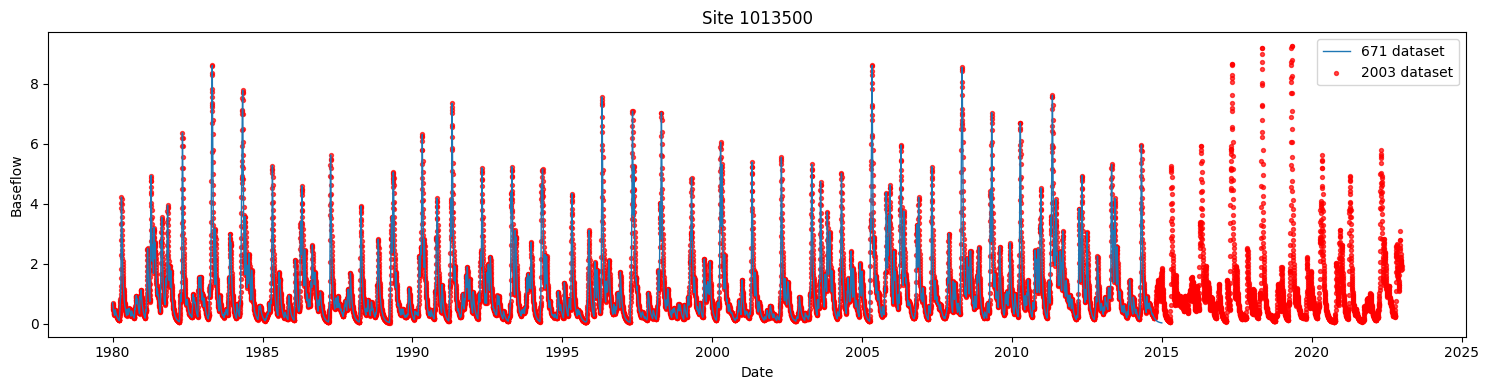

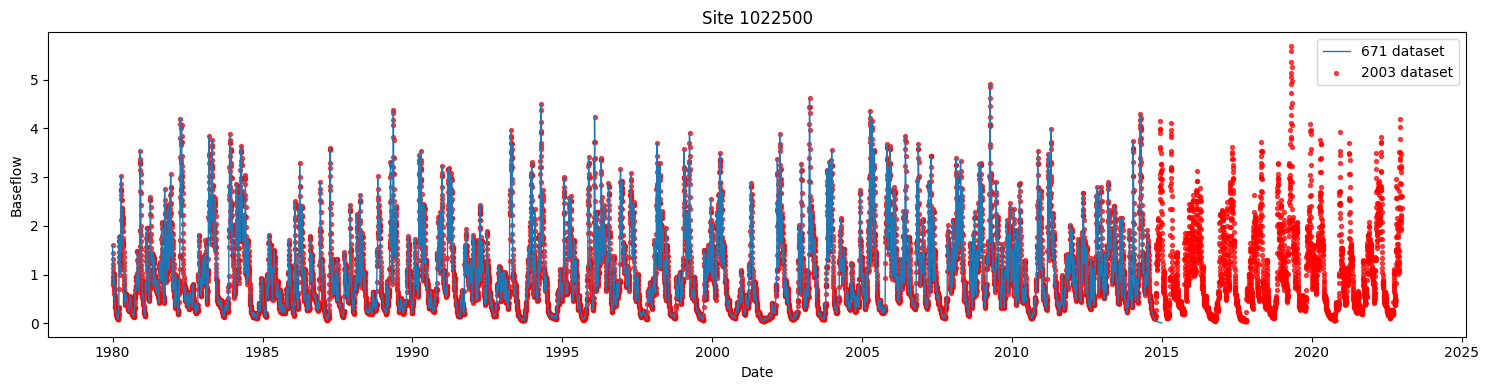

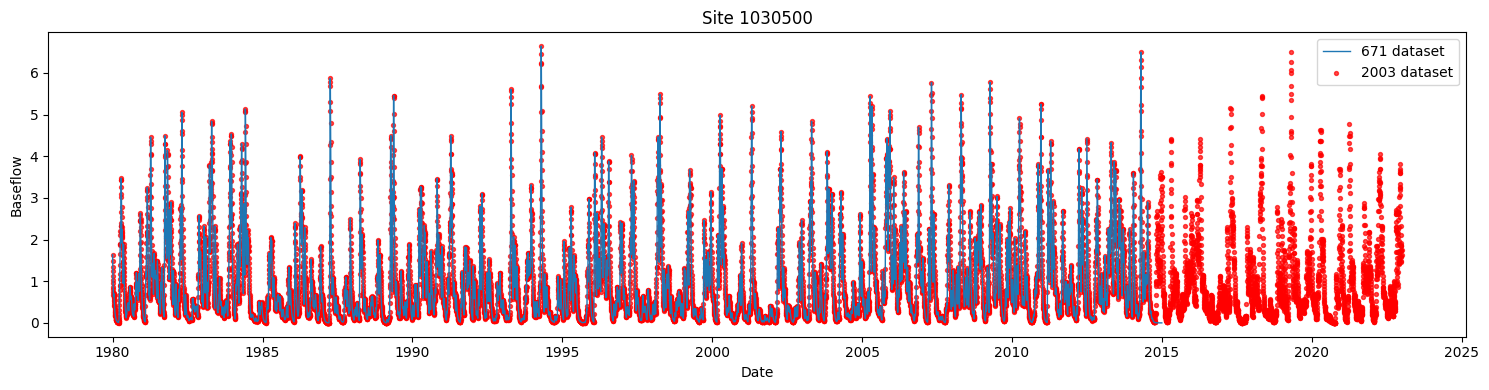

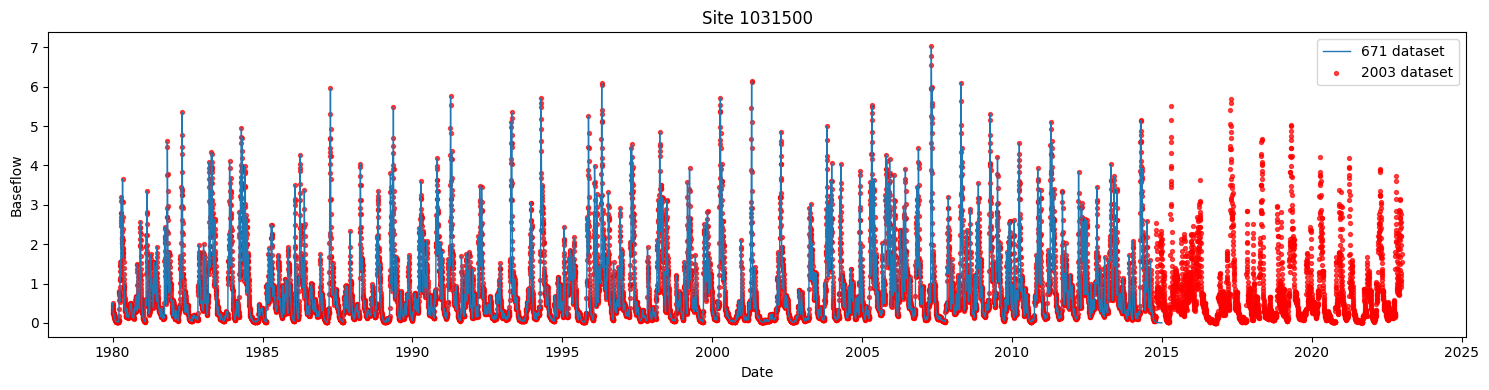

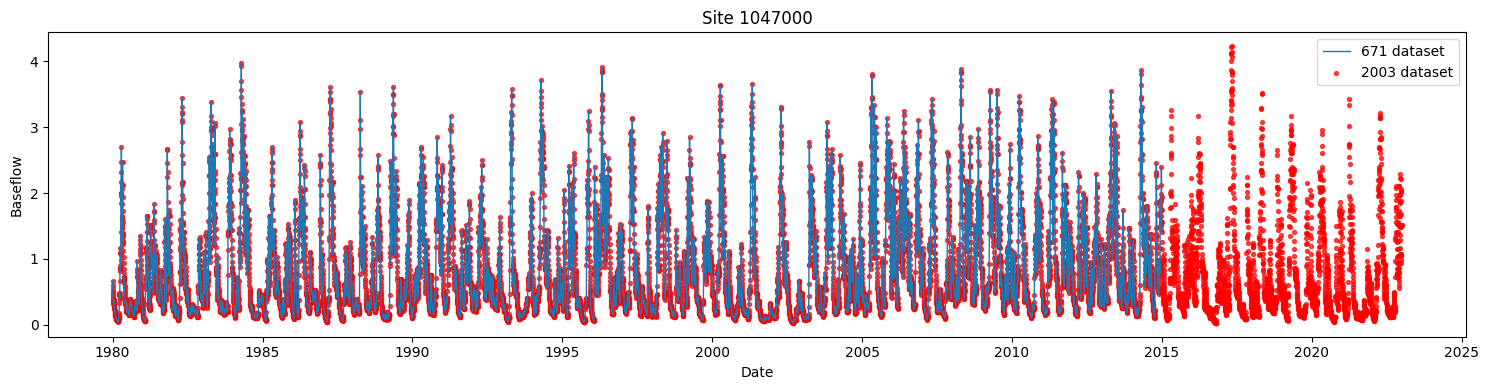

In [ ]:
####USGS SEPARATION on 2003 checking data
import numpy as np
import matplotlib.pyplot as plt

# --------------------------------------------------
# Load files
# --------------------------------------------------

file_671 = "/scratch/data/CAMELS_FORCING/daymet_19800101_20141231_forcing_671_usgs.npy"
file_2003 = "/scratch/data/CAMELS_DAYMET/f2003_daymet_20240826_baseflow.npy"forc671 = np.load(file_671, allow_pickle=True)
forc2003 = np.load(file_2003, allow_pickle=True)

print(forc671.shape)
print(forc2003.shape)

# --------------------------------------------------
# Site numbers (-2 variable)
# --------------------------------------------------

site671 = forc671[:, 0, -2].astype(int)
site2003 = forc2003[:, 0, 8].astype(int)

lookup671 = {s: i for i, s in enumerate(site671)}
lookup2003 = {s: i for i, s in enumerate(site2003)}

common_sites = sorted(set(site671) & set(site2003))

print(f"Common basins: {len(common_sites)}")

# --------------------------------------------------
# Dates
# --------------------------------------------------

# 671 dataset: fixed daily period
dates671 = pd.date_range("1980-01-01", "2014-12-31", freq="D")

# Ensure length matches
assert len(dates671) == forc671.shape[1]

# --------------------------------------------------
# Plot first 5 common basins
# --------------------------------------------------

for site in common_sites[:5]:

    i671 = lookup671[site]
    i2003 = lookup2003[site]

    bf671 = forc671[i671, :, -1].astype(float)
    bf2003 = forc2003[i2003, :, -1].astype(float)

    # Dates from 2003 dataset
    dates2003 = pd.to_datetime(
        forc2003[i2003, :, 7].astype(int).astype(str),
        format="%Y%m%d"
    )

    plt.figure(figsize=(15, 4))

    plt.plot(dates671, bf671, label="671 dataset", lw=1)
    plt.scatter(
    dates2003,
    bf2003,
    label="2003 dataset",
    s=8,          # marker size
    color="red",
    alpha=0.7
)

    plt.title(f"Site {site}")
    plt.xlabel("Date")
    plt.ylabel("Baseflow")
    plt.legend()

    plt.tight_layout()
    plt.show()
